# Aula 14 — scikit-learn: Fluxo de Trabalho em ML

**Especialização em Ciência de Dados · Análise e Ciência de Dados · IFRN**
Unidade 4 — Aprendizado de Máquina Aplicado (primeira aula)

### Caso da aula — quem vai cancelar o app de música?
O aplicativo de música **fictício** da Aula 12 cresceu: agora temos **1.500 usuários** e sabemos quem **cancelou a conta** no mês seguinte (`cancelou = 1`). A empresa quer um modelo que, a partir do comportamento de hoje, aponte quem tem **risco de cancelar**, para oferecer um desconto antes que isso aconteça.

É um problema de **classificação binária**. Vamos percorrer o **fluxo de trabalho completo** do scikit-learn:

`dados → X e y → treino/teste → baseline → pipeline (pré-processamento + modelo) → métricas → validação cruzada → comparação de modelos`

No final, um exemplo curto de **regressão** (prever o tempo de entrega da hamburgueria da Aula 12) mostra as métricas RMSE e R².

> Dados **sintéticos** (gerados por `gerar_dados.py`, semente fixa). Nenhum registro é real.

### Roteiro (1h30)

| Tempo | Parte | O que você vai ver |
|---|---|---|
| 0–10 min | 0. Dados e pergunta | alvo, proporção das classes, valores faltantes |
| 10–20 min | 1. A API do scikit-learn | `fit`, `predict`, `predict_proba`, `transform` |
| 20–30 min | 2. Treino/teste e baseline | `train_test_split` estratificado, `DummyClassifier`, paradoxo da acurácia |
| 30–45 min | 3. Pipeline | `ColumnTransformer` (imputação, padronização, one-hot) + `LogisticRegression` |
| 45–60 min | 4. Métricas de classificação | matriz de confusão, acurácia, precisão, recall, F1, ROC-AUC, limiar |
| 60–75 min | 5. Validação cruzada | `StratifiedKFold`, `cross_validate`, comparação de 3 modelos |
| 75–85 min | 6. Regressão | pipeline com `LinearRegression`, MAE, RMSE, R² |
| 85–90 min | Fechamento | checklist do fluxo de ML e trabalho prático |

### Dicionário — `dados/app_musica_churn.csv`
| Coluna | Descrição |
|---|---|
| `idade` | idade em anos |
| `plano` | Gratuito ou Premium |
| `dispositivo` | Celular, Computador, Smart TV |
| `meses_conta` | há quantos meses o usuário tem conta |
| `horas_semana` | horas de música ouvidas por semana |
| `playlists_criadas` | playlists criadas |
| `anuncios_semana` | anúncios ouvidos por semana (Premium = 0) |
| `dias_sem_acessar` | dias desde o último acesso |
| `chamados_suporte` | chamados abertos no suporte no último mês |
| `satisfacao` | nota de satisfação 0–10 (≈ 4% não responderam) |
| **`cancelou`** | **alvo**: 1 = cancelou no mês seguinte |

## Parte 0 — Dados e pergunta

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["axes.titleweight"] = "bold"
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
SEMENTE = 42          # fixar a semente torna os resultados reproduzíveis

df = pd.read_csv("dados/app_musica_churn.csv")
print(df.shape)
df.head()

(1500, 12)


,usuario_id,idade,plano,dispositivo,meses_conta,horas_semana,playlists_criadas,anuncios_semana,dias_sem_acessar,chamados_suporte,satisfacao,cancelou
0,1,23,Gratuito,Celular,6,12.5,4,106,3,0,3.8,0
1,2,57,Premium,Smart TV,11,14.7,3,0,4,0,9.1,0
2,3,48,Gratuito,Computador,19,11.1,1,101,1,0,4.1,0
3,4,34,Gratuito,Computador,57,10.6,2,98,17,0,4.1,0
4,5,20,Gratuito,Computador,65,15.8,7,178,1,0,3.8,0


In [2]:
print("Proporção das classes (alvo):")
print(df["cancelou"].value_counts(normalize=True).round(3))
print("\nValores faltantes por coluna:")
print(df.isna().sum()[df.isna().sum() > 0])

Proporção das classes (alvo):
cancelou
0    0.731
1    0.269
Name: proportion, dtype: float64

Valores faltantes por coluna:
satisfacao    60
dtype: int64


**Leitura:** cerca de **27% cancelaram** — as classes são **desbalanceadas** (há mais "ficou" do que "cancelou"). Isso vai importar na escolha das métricas. E a `satisfacao` tem valores faltantes: o modelo não aceita `NaN`, então precisaremos **imputar**.

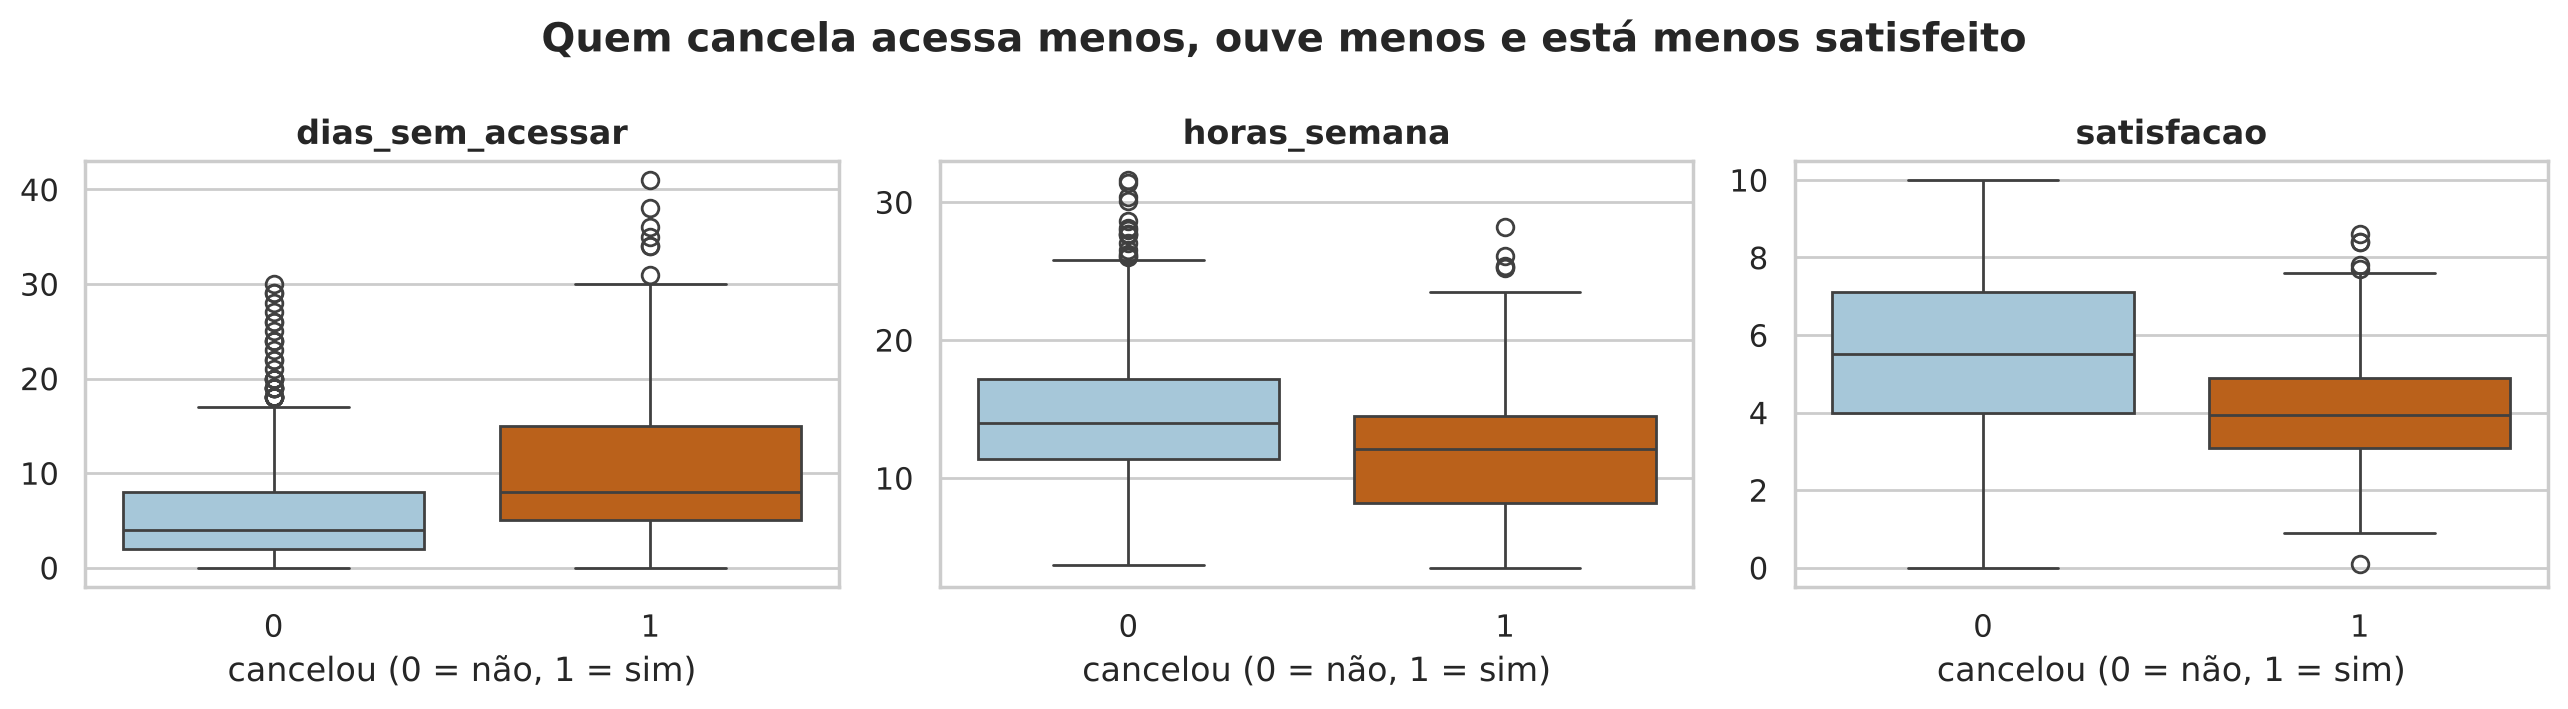

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ["dias_sem_acessar", "horas_semana", "satisfacao"]):
    sns.boxplot(data=df, x="cancelou", y=col, hue="cancelou", palette=["#9ecae1", "#d55e00"], legend=False, ax=ax)
    ax.set(title=col, xlabel="cancelou (0 = não, 1 = sim)", ylabel="")
fig.suptitle("Quem cancela acessa menos, ouve menos e está menos satisfeito", fontweight="bold")
fig.tight_layout(); plt.show()

## Parte 1 — A API do scikit-learn

Todo objeto do scikit-learn segue o mesmo "contrato":

| Tipo | Métodos | Exemplos |
|---|---|---|
| **Estimador** (modelo) | `fit(X, y)` aprende; `predict(X)` prevê; `predict_proba(X)` dá probabilidades; `score(X, y)` | `LogisticRegression`, `DecisionTreeClassifier`, `LinearRegression` |
| **Transformador** | `fit(X)` aprende parâmetros; `transform(X)` aplica; `fit_transform(X)` faz os dois | `StandardScaler`, `OneHotEncoder`, `SimpleImputer` |

Convenções: `X` = matriz de **atributos** (linhas = exemplos, colunas = variáveis); `y` = **alvo**. O que o modelo aprende fica em atributos terminados em `_` (ex.: `coef_`, `mean_`).

In [4]:
from sklearn.preprocessing import StandardScaler

esc = StandardScaler()
esc.fit(df[["horas_semana", "dias_sem_acessar"]])          # aprende média e desvio-padrão
print("médias aprendidas:", esc.mean_.round(2), "| desvios:", esc.scale_.round(2))
esc.transform(df[["horas_semana", "dias_sem_acessar"]].head(3)).round(2)   # aplica (z-score)

médias aprendidas: [13.76  6.65] | desvios: [4.5  6.26]


array([[-0.28, -0.58],
       [ 0.21, -0.42],
       [-0.59, -0.9 ]])

## Parte 2 — Treino/teste e baseline

### 2.1 Separar X e y, e depois treino e teste
O modelo deve ser avaliado em dados que **não viu** no treino. Separamos 25% para teste com `stratify=y`, que mantém a mesma proporção de cancelamentos nos dois conjuntos.

> ⚠️ **Vazamento de dados (data leakage):** tudo o que "aprende" com os dados (médias da padronização, mediana da imputação, categorias do one-hot) deve ser ajustado **só no treino**. O pipeline (Parte 3) garante isso automaticamente.

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["usuario_id", "cancelou"])     # o id não é informação útil
y = df["cancelou"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEMENTE)

print(f"treino: {X_treino.shape}  | teste: {X_teste.shape}")
print(f"taxa de cancelamento — treino: {y_treino.mean():.3f} | teste: {y_teste.mean():.3f}")

treino: (1125, 10)  | teste: (375, 10)
taxa de cancelamento — treino: 0.268 | teste: 0.269


### 2.2 Baseline: o modelo "preguiçoso"
Antes de qualquer modelo, pergunte: *quanto acerta quem chuta sempre a classe mais comum?* O `DummyClassifier` responde.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

dummy = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)
pred_dummy = dummy.predict(X_teste)
print(f"Acurácia do baseline: {accuracy_score(y_teste, pred_dummy):.3f}")
print(f"Recall (cancelamentos encontrados): {recall_score(y_teste, pred_dummy):.3f}")

Acurácia do baseline: 0.731
Recall (cancelamentos encontrados): 0.000


**Paradoxo da acurácia:** o baseline acerta **73%** sem encontrar **nenhum** cliente que vai cancelar. Em problemas desbalanceados, acurácia sozinha engana. Todo modelo deve ser comparado com esse baseline.

## Parte 3 — Pré-processamento + modelo em um Pipeline

Colunas diferentes pedem tratamentos diferentes:
* **numéricas**: imputar faltantes (mediana) e padronizar (`StandardScaler`);
* **categóricas**: transformar em colunas 0/1 (`OneHotEncoder`).

O `ColumnTransformer` aplica cada tratamento às suas colunas; o `Pipeline` encadeia pré-processamento e modelo em **um único estimador** — com um só `fit` e um só `predict`, e sem vazamento.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

numericas = ["idade", "meses_conta", "horas_semana", "playlists_criadas",
             "anuncios_semana", "dias_sem_acessar", "chamados_suporte", "satisfacao"]
categoricas = ["plano", "dispositivo"]

preprocess = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                      ("padronizar", StandardScaler())]), numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas),
])

modelo = Pipeline([
    ("preprocess", preprocess),
    ("classificador", LogisticRegression(max_iter=1000)),
])
modelo.fit(X_treino, y_treino)     # imputação, padronização e one-hot aprendem SÓ no treino
modelo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('classificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['idade','plano','dispositivo',...,'dias_sem_acessar','chamados_suporte', 'satisfacao']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

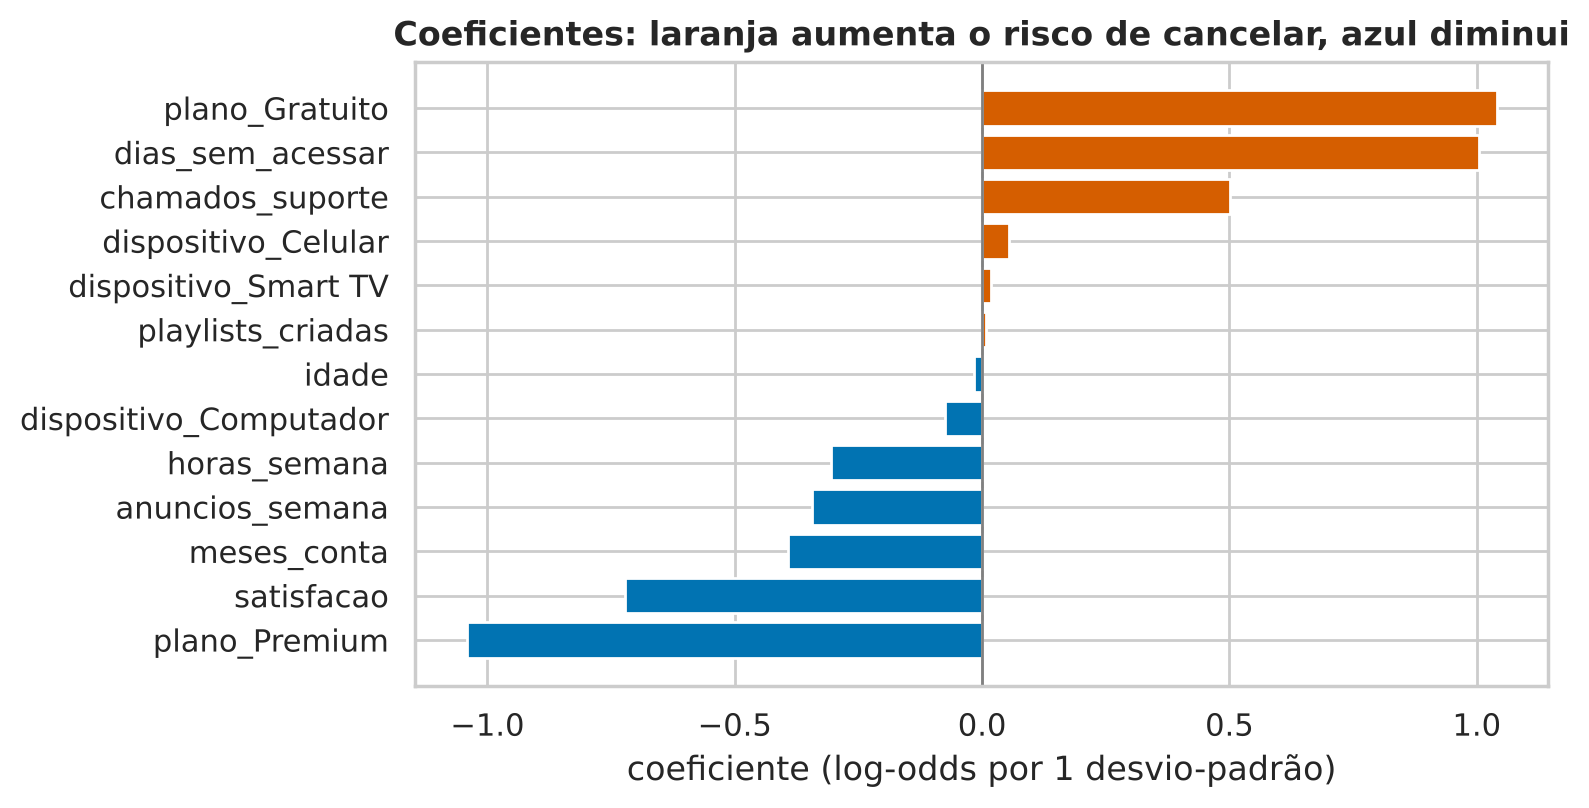

In [8]:
# O que o modelo aprendeu: coeficientes da regressão logística (variáveis padronizadas)
nomes = modelo.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(modelo.named_steps["classificador"].coef_[0], index=nomes).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh([n.split("__")[1] for n in coefs.index], coefs.values,
        color=["#0173b2" if v < 0 else "#d55e00" for v in coefs.values])
ax.axvline(0, color="gray", lw=1)
ax.set(title="Coeficientes: laranja aumenta o risco de cancelar, azul diminui", xlabel="coeficiente (log-odds por 1 desvio-padrão)")
fig.tight_layout(); fig.savefig(FIG / "02_coeficientes.png", dpi=180, bbox_inches="tight"); plt.show()

## Parte 4 — Métricas de classificação

### 4.1 Matriz de confusão
|  | previsto: ficou (0) | previsto: cancelou (1) |
|---|---|---|
| **real: ficou (0)** | VN (verdadeiro negativo) | FP (falso alarme) |
| **real: cancelou (1)** | FN (cancelamento perdido) | VP (verdadeiro positivo) |

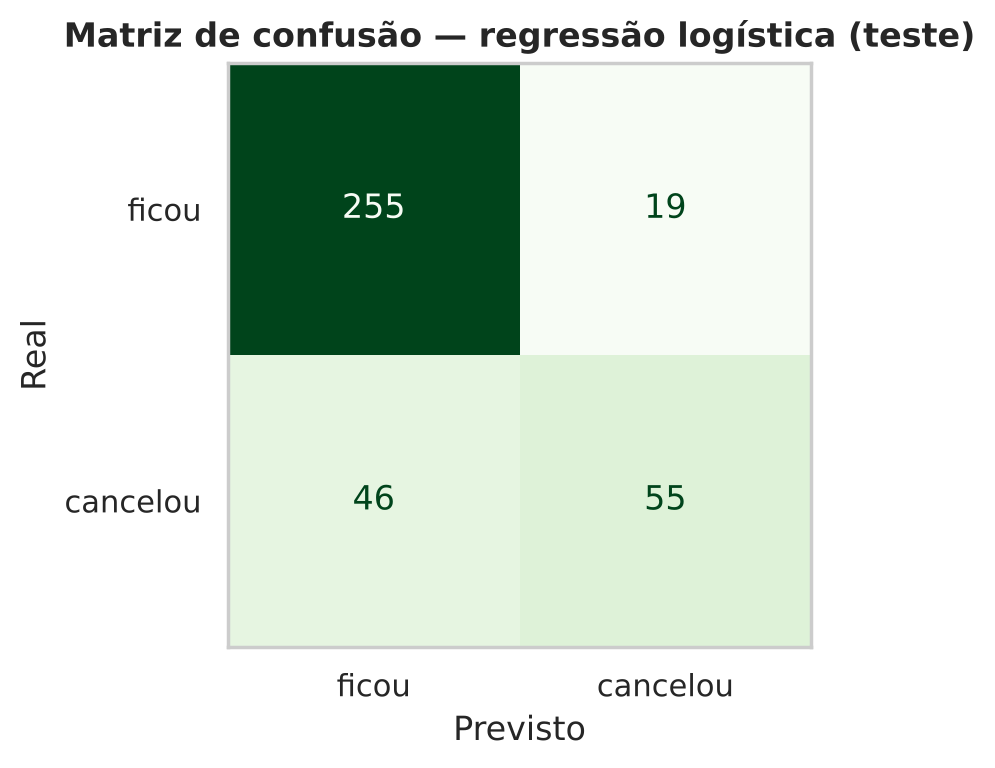

VN=255  FP=19  FN=46  VP=55


In [9]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             precision_score, f1_score, roc_auc_score)

pred = modelo.predict(X_teste)
fig, ax = plt.subplots(figsize=(4.8, 4))
ConfusionMatrixDisplay.from_predictions(y_teste, pred, display_labels=["ficou", "cancelou"],
                                        cmap="Greens", colorbar=False, ax=ax)
ax.set(title="Matriz de confusão — regressão logística (teste)", xlabel="Previsto", ylabel="Real")
ax.grid(False); fig.tight_layout(); fig.savefig(FIG / "03_matriz_confusao.png", dpi=180, bbox_inches="tight"); plt.show()
vn, fp, fn, vp = confusion_matrix(y_teste, pred).ravel()
print(f"VN={vn}  FP={fp}  FN={fn}  VP={vp}")

### 4.2 Acurácia, precisão, recall e F1

| Métrica | Fórmula | Pergunta que responde |
|---|---|---|
| **Acurácia** | (VP + VN) / total | quantos acertos no geral? |
| **Precisão** | VP / (VP + FP) | dos que o modelo apontou como "vai cancelar", quantos cancelaram? |
| **Recall** (sensibilidade) | VP / (VP + FN) | dos que cancelaram, quantos o modelo encontrou? |
| **F1** | 2 · P · R / (P + R) | equilíbrio entre precisão e recall (média harmônica) |

In [10]:
proba = modelo.predict_proba(X_teste)[:, 1]          # probabilidade de cancelar
metricas = pd.DataFrame({
    "baseline (Dummy)": [accuracy_score(y_teste, pred_dummy), precision_score(y_teste, pred_dummy, zero_division=0),
                         recall_score(y_teste, pred_dummy), f1_score(y_teste, pred_dummy), 0.5],
    "regressão logística": [accuracy_score(y_teste, pred), precision_score(y_teste, pred),
                            recall_score(y_teste, pred), f1_score(y_teste, pred), roc_auc_score(y_teste, proba)],
}, index=["acurácia", "precisão", "recall", "F1", "ROC-AUC"]).round(3)
metricas

,baseline (Dummy),regressão logística
acurácia,0.731,0.827
precisão,0.000,0.743
recall,0.000,0.545
F1,0.000,0.629
ROC-AUC,0.500,0.831


In [11]:
print(classification_report(y_teste, pred, target_names=["ficou", "cancelou"], digits=3))

              precision    recall  f1-score   support

       ficou      0.847     0.931     0.887       274
    cancelou      0.743     0.545     0.629       101

    accuracy                          0.827       375
   macro avg      0.795     0.738     0.758       375
weighted avg      0.819     0.827     0.817       375



### 4.3 ROC-AUC: avaliando as probabilidades
O `predict` usa o limiar 0,5: probabilidade ≥ 0,5 → "cancela". A **curva ROC** mostra o que acontece com **todos** os limiares: no eixo y, o recall (taxa de verdadeiros positivos); no x, a taxa de falsos positivos. A **área sob a curva (AUC)** resume: 0,5 = chute; 1,0 = separação perfeita. Interpretação: a AUC é a probabilidade de o modelo dar um risco maior a um cliente que cancelou do que a um que ficou.

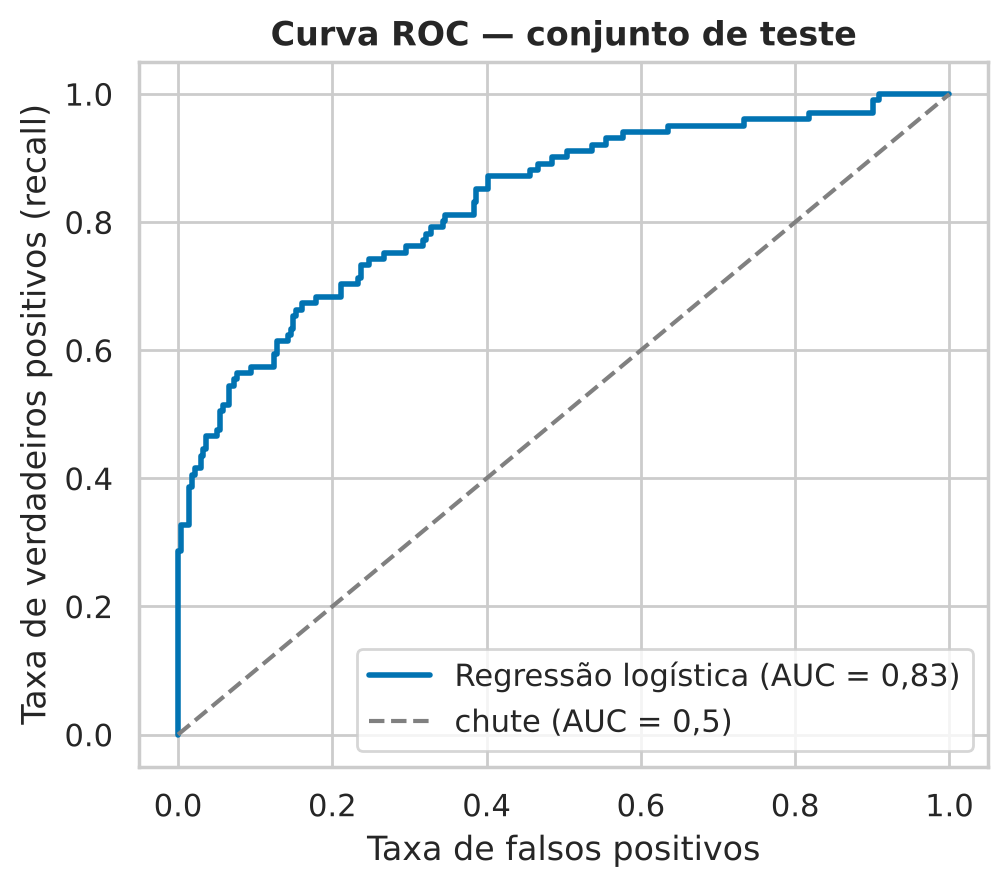

In [12]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
from sklearn.metrics import roc_curve
fpr, tpr, _ = roc_curve(y_teste, proba)
ax.plot(fpr, tpr, color="#0173b2", lw=2, label=f"Regressão logística (AUC = {roc_auc_score(y_teste, proba):.2f})".replace(".", ","))
ax.plot([0, 1], [0, 1], "--", color="gray", label="chute (AUC = 0,5)")
ax.set(title="Curva ROC — conjunto de teste", xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos (recall)")
ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "04_roc.png", dpi=180, bbox_inches="tight"); plt.show()

### 4.4 O limiar de decisão é uma escolha de negócio
Perder um cliente que ia cancelar (FN) costuma custar mais do que oferecer um desconto a quem ficaria (FP). Baixar o limiar aumenta o recall e reduz a precisão:

In [13]:
linhas = []
for limiar in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (proba >= limiar).astype(int)
    linhas.append([limiar, precision_score(y_teste, p), recall_score(y_teste, p), f1_score(y_teste, p), p.sum()])
tab_limiar = pd.DataFrame(linhas, columns=["limiar", "precisão", "recall", "F1", "clientes apontados"]).round(3)
tab_limiar

,limiar,precisão,recall,F1,clientes apontados
0,0.2,0.460,0.802,0.585,176
1,0.3,0.530,0.703,0.604,134
2,0.4,0.639,0.614,0.626,97
3,0.5,0.743,0.545,0.629,74
4,0.6,0.875,0.416,0.564,48
5,0.7,0.943,0.327,0.485,35


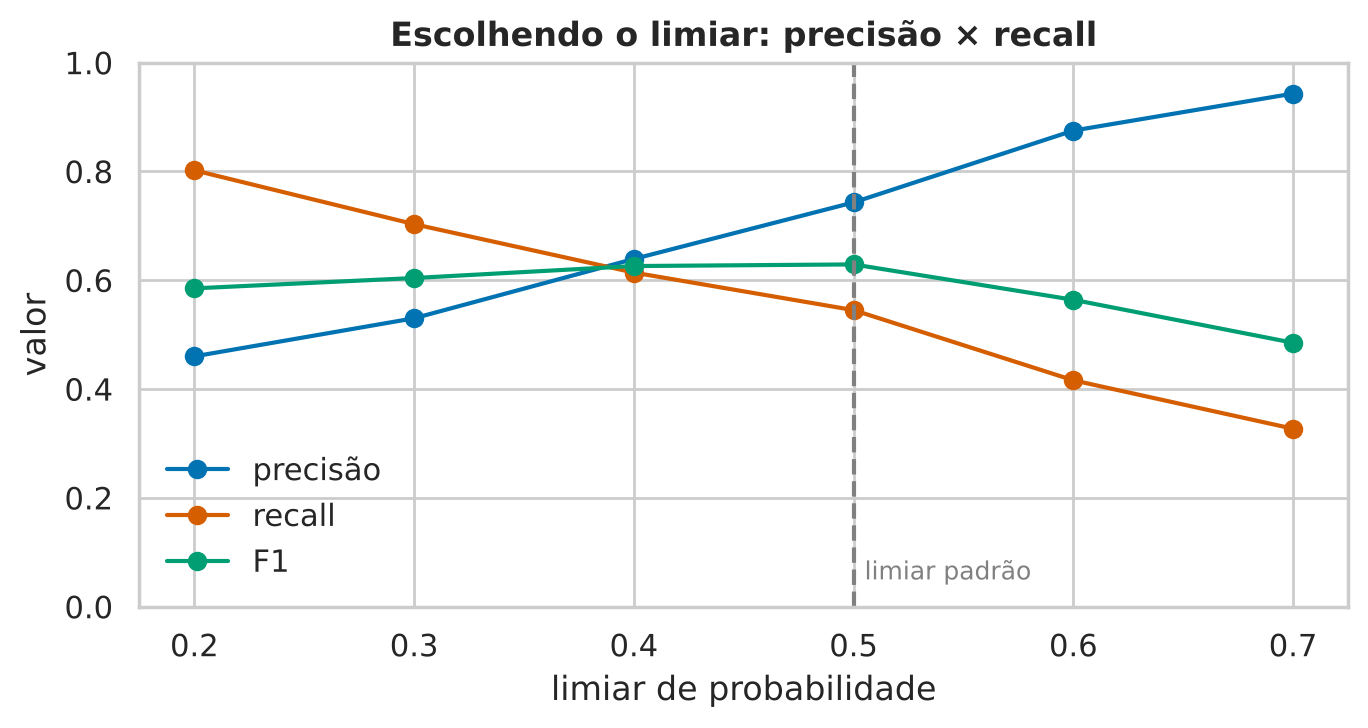

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for col, cor in [("precisão", "#0173b2"), ("recall", "#d55e00"), ("F1", "#029e73")]:
    ax.plot(tab_limiar["limiar"], tab_limiar[col], marker="o", label=col, color=cor)
ax.axvline(0.5, ls="--", color="gray"); ax.text(0.505, 0.05, "limiar padrão", color="gray", fontsize=9)
ax.set(title="Escolhendo o limiar: precisão × recall", xlabel="limiar de probabilidade", ylabel="valor", ylim=(0, 1))
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG / "05_limiar.png", dpi=180, bbox_inches="tight"); plt.show()

## Parte 5 — Validação cruzada e comparação de modelos

Uma única divisão treino/teste depende da sorte do sorteio. Na **validação cruzada k-fold**, o treino é dividido em *k* partes; o modelo é treinado *k* vezes, cada vez avaliado em uma parte diferente. O resultado é **média ± desvio-padrão**. Com classes desbalanceadas, use `StratifiedKFold`.

> O conjunto de **teste fica guardado** até o fim: a validação cruzada roda só no treino e serve para **escolher** o modelo.

In [15]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
candidatos = {
    "Baseline (Dummy)": DummyClassifier(strategy="most_frequent"),
    "Regressão logística": LogisticRegression(max_iter=1000),
    "Árvore de decisão": DecisionTreeClassifier(max_depth=4, random_state=SEMENTE),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEMENTE),
}
resultados, folds = [], []
for nome, clf in candidatos.items():
    pipe = Pipeline([("preprocess", preprocess), ("classificador", clf)])
    r = cross_validate(pipe, X_treino, y_treino, cv=cv, scoring=["accuracy", "f1", "roc_auc"])
    resultados.append({"modelo": nome,
                       **{f"{m} (média)": r[f"test_{m}"].mean() for m in ["accuracy", "f1", "roc_auc"]},
                       "roc_auc (dp)": r["test_roc_auc"].std()})
    folds += [{"modelo": nome, "fold": i + 1, "ROC-AUC": v} for i, v in enumerate(r["test_roc_auc"])]
tab_cv = pd.DataFrame(resultados).set_index("modelo").round(3)
tab_cv

,accuracy (média),f1 (média),roc_auc (média),roc_auc (dp)
modelo,,,,
Baseline (Dummy),0.732,0.000,0.500,0.000
Regressão logística,0.803,0.564,0.845,0.029
Árvore de decisão,0.787,0.527,0.778,0.032
Random forest,0.806,0.556,0.838,0.026


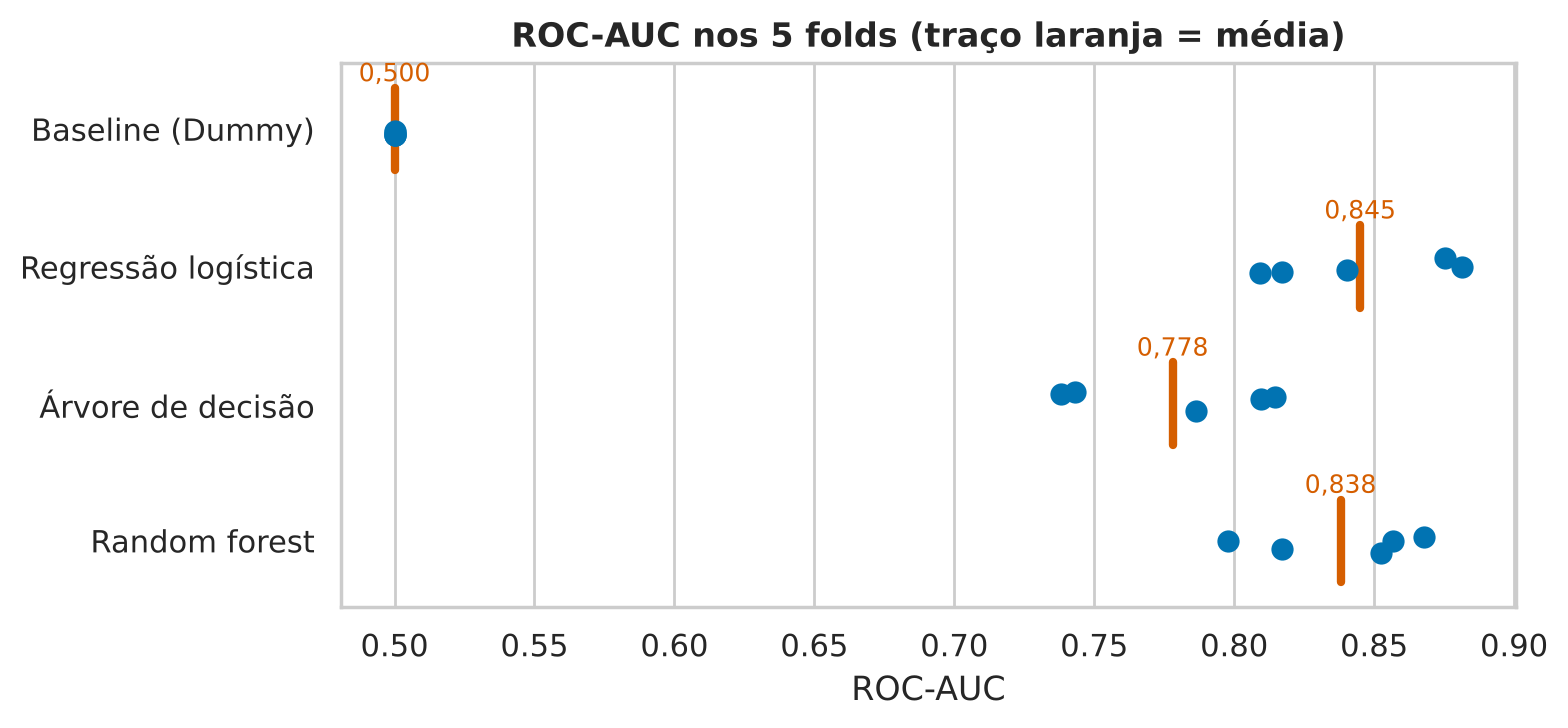

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.8))
dfolds = pd.DataFrame(folds)
sns.stripplot(data=dfolds, x="ROC-AUC", y="modelo", size=8, color="#0173b2", ax=ax)
for i, nome in enumerate(candidatos):
    mu = tab_cv.loc[nome, "roc_auc (média)"]
    ax.plot([mu, mu], [i - 0.3, i + 0.3], color="#d55e00", lw=3)
    ax.text(mu, i - 0.35, f"{mu:.3f}".replace(".", ","), ha="center", fontsize=9, color="#d55e00")
ax.set(title="ROC-AUC nos 5 folds (traço laranja = média)", xlabel="ROC-AUC", ylabel="")
fig.tight_layout(); fig.savefig(FIG / "06_validacao_cruzada.png", dpi=180, bbox_inches="tight"); plt.show()

**Escolha:** a regressão logística tem a maior ROC-AUC média e variação pequena entre os folds; a random forest fica perto; a árvore rasa fica atrás; o baseline tem AUC 0,5. Só **agora** avaliamos o modelo escolhido, uma única vez, no teste (feito na Parte 4).

## Parte 6 — Regressão: prever o tempo de entrega (Aula 12)

Quando o alvo é **numérico**, o fluxo é o mesmo — muda o estimador e as métricas:

| Métrica | O que mede | Unidade |
|---|---|---|
| **MAE** | erro absoluto médio | a do alvo (min) |
| **RMSE** | raiz do erro quadrático médio — pune mais os erros grandes | a do alvo (min) |
| **R²** | proporção da variação do alvo explicada pelo modelo (1 = perfeito; 0 = igual a prever sempre a média) | sem unidade |

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score

dl = pd.read_csv("dados/delivery_hamburgueria.csv")
Xr = dl[["distancia_km", "itens", "chuva", "turno", "veiculo", "dia_semana"]]
yr = dl["tempo_entrega_min"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.25, random_state=SEMENTE)

reg = Pipeline([
    ("preprocess", ColumnTransformer([
        ("num", StandardScaler(), ["distancia_km", "itens"]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["chuva", "turno", "veiculo", "dia_semana"])])),
    ("regressor", LinearRegression()),
]).fit(Xr_tr, yr_tr)
pr = reg.predict(Xr_te)
print(f"MAE  = {mean_absolute_error(yr_te, pr):.2f} min")
print(f"RMSE = {root_mean_squared_error(yr_te, pr):.2f} min")
print(f"R²   = {r2_score(yr_te, pr):.3f}")
print(f"Baseline (prever sempre a média do treino): RMSE = {root_mean_squared_error(yr_te, np.full(len(yr_te), yr_tr.mean())):.2f} min")
cv_rmse = -cross_val_score(reg, Xr_tr, yr_tr, cv=5, scoring="neg_root_mean_squared_error")
print(f"RMSE na validação cruzada (5 folds): {cv_rmse.mean():.2f} ± {cv_rmse.std():.2f} min")

MAE  = 3.94 min
RMSE = 6.84 min
R²   = 0.595
Baseline (prever sempre a média do treino): RMSE = 10.75 min
RMSE na validação cruzada (5 folds): 5.88 ± 1.01 min


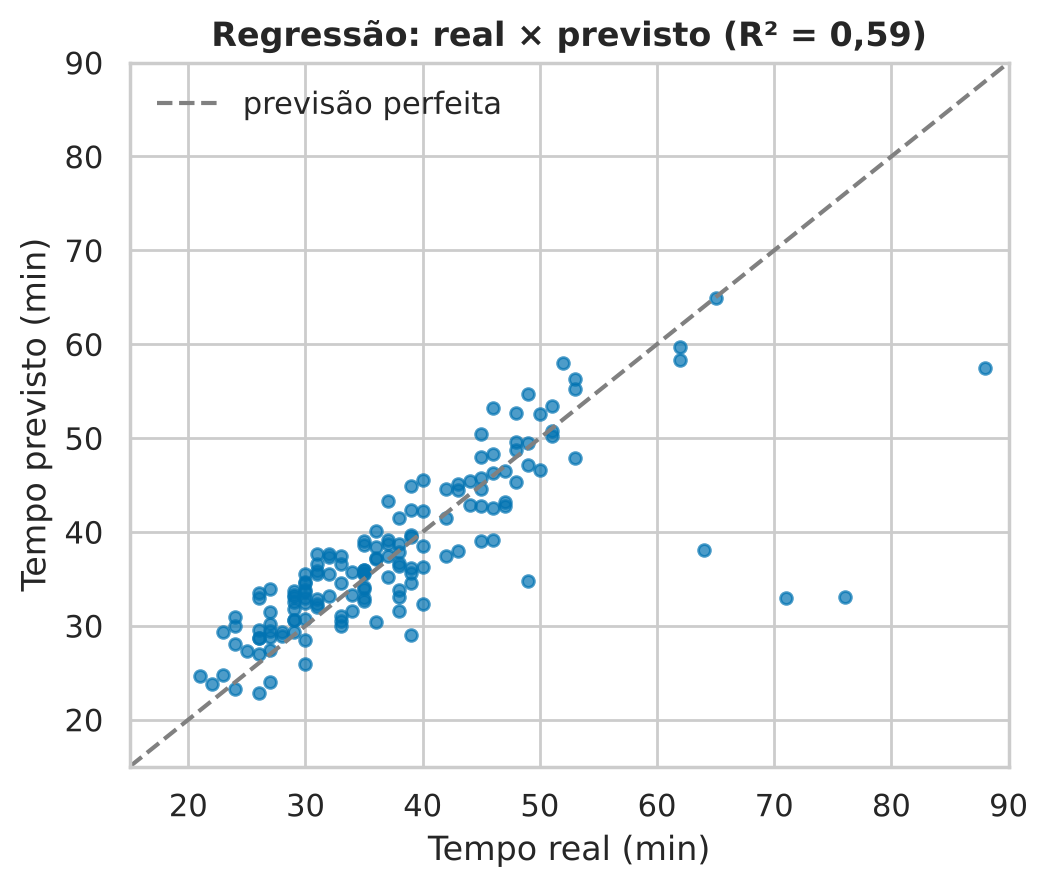

In [18]:
fig, ax = plt.subplots(figsize=(5.4, 4.6))
ax.scatter(yr_te, pr, s=18, alpha=.7, color="#0173b2")
lim = [15, 90]; ax.plot(lim, lim, "--", color="gray", label="previsão perfeita")
ax.set(xlim=lim, ylim=lim, title=f"Regressão: real × previsto (R² = {r2_score(yr_te, pr):.2f})".replace(".", ","),
       xlabel="Tempo real (min)", ylabel="Tempo previsto (min)")
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG / "07_regressao.png", dpi=180, bbox_inches="tight"); plt.show()

**Leitura:** o modelo erra em média cerca de 4 min (MAE) e tem RMSE de 6,8 min, contra 10,8 min do baseline que chuta sempre a média; R² de 0,59. Os pontos acima da diagonal à direita são os atrasos excepcionais: nenhuma variável do modelo os explica (o RMSE, que pune erros grandes, fica bem acima do MAE por causa deles). `neg_root_mean_squared_error`: o scikit-learn sempre *maximiza* o *score*, por isso erros aparecem com sinal negativo.

## Fechamento — o fluxo de trabalho em ML

1. Defina a **pergunta** e o **alvo**; verifique o balanceamento das classes.
2. Separe **X** e **y**; separe **treino/teste** (estratificado na classificação) e guarde o teste.
3. Calcule um **baseline**.
4. Monte um **pipeline** (pré-processamento + modelo) — nada de ajustar transformações fora dele.
5. Compare modelos com **validação cruzada** no treino, usando a(s) métrica(s) certa(s) para o problema.
6. Avalie o escolhido **uma vez** no teste; interprete matriz de confusão, ROC-AUC (ou RMSE/R²).
7. Ajuste o **limiar** de acordo com o custo dos erros.

**Trabalho prático:** `Aula14_Trabalho_Pratico.ipynb` — aplique esse fluxo para prever clientes insatisfeitos da hamburgueria. **Entrega no Moodle.**